In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.metrics import mean_absolute_percentage_error, r2_score

import sys
from pathlib import Path

# Dynamically link project root to import config settings
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from config.settings import DATABASE_URL

# Connect to PostgreSQL and load clean Kenya listings
engine = create_engine(DATABASE_URL)
df_kenya = pd.read_sql("SELECT * FROM clean_kenya_listings;", engine)
print(f"Loaded {len(df_kenya)} records from clean_kenya_listings.")
df_kenya.head(3)

Loaded 487 records from clean_kenya_listings.


,id,listing_url,source_site,make,model,year,mileage_km,engine_cc,fuel_type,transmission,yard_price_kes
0,14,https://jiji.co.ke/ridgeways/cars/volkswagen-t...,JIJI_KENYA,VOLKSWAGEN,TIGUAN,2019,0,2000,DIESEL,AUTOMATIC,4200000.0
1,15,https://jiji.co.ke/upperhill/cars/toyota-hilux...,JIJI_KENYA,TOYOTA,HILUX,2018,98720,2400,DIESEL,AUTOMATIC,4700000.0
2,16,https://jiji.co.ke/kilimani/cars/toyota-probox...,JIJI_KENYA,TOYOTA,PROBOX,2019,0,1500,PETROL,AUTOMATIC,1400000.0


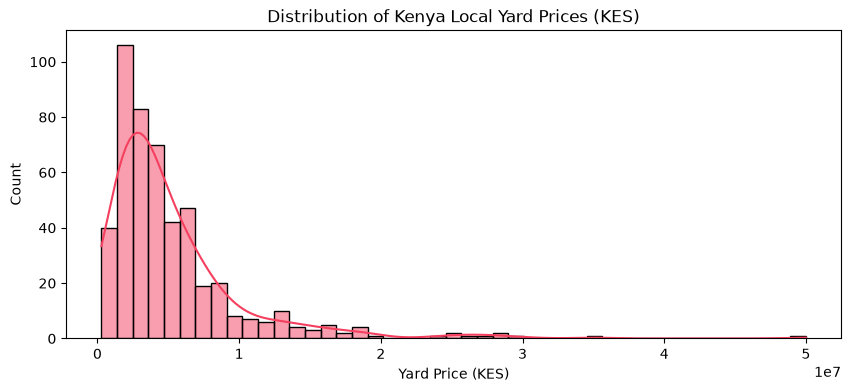

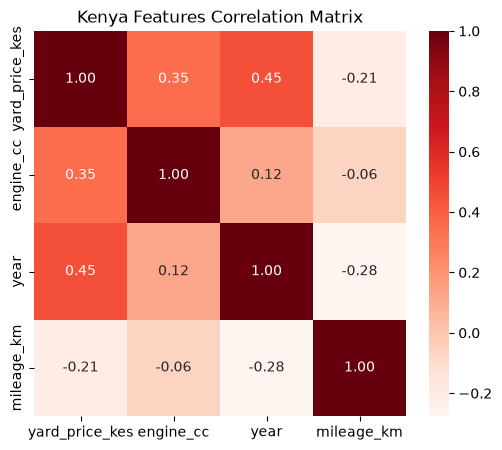

In [2]:
# 1. Distribution of Kenya Local Yard Prices (KES)
plt.figure(figsize=(10, 4))
sns.histplot(pd.to_numeric(df_kenya['yard_price_kes'], errors='coerce'), kde=True, color='#f43f5e')
plt.title("Distribution of Kenya Local Yard Prices (KES)")
plt.xlabel("Yard Price (KES)")
plt.ylabel("Count")
plt.show()

# 2. Correlation Matrix of Numerical Features
num_cols = ['yard_price_kes', 'engine_cc', 'year', 'mileage_km']
df_num = df_kenya[num_cols].apply(pd.to_numeric, errors='coerce')

plt.figure(figsize=(6, 5))
sns.heatmap(df_num.corr(), annot=True, cmap='Reds', fmt=".2f")
plt.title("Kenya Features Correlation Matrix")
plt.show()

In [3]:
# Define features and categorical columns
ke_features = ['engine_cc', 'year', 'mileage_km']
ke_cats = ['make', 'model', 'fuel_type', 'transmission', 'source_site']

# Clean and coerce numerical features with median imputation
for col in ke_features:
    df_kenya[col] = pd.to_numeric(df_kenya[col], errors='coerce').fillna(df_kenya[col].median())

# Handle categorical variables with One-Hot Encoding
X_raw = df_kenya[ke_cats + ke_features].fillna('UNKNOWN')
X = pd.get_dummies(X_raw, drop_first=True)

# Define target variable (y)
y = pd.to_numeric(df_kenya['yard_price_kes'], errors='coerce').fillna(df_kenya['yard_price_kes'].median())

# Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set shape: {X_train.shape}, Testing set shape: {X_test.shape}")

Training set shape: (389, 188), Testing set shape: (98, 188)


In [4]:
# Initialize multi-framework benchmark dictionary
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    # Calculate evaluation metrics
    mape = mean_absolute_percentage_error(y_test, preds) * 100
    r2 = r2_score(y_test, preds)
    
    results[name] = {"MAPE": mape, "R2": r2}
    print(f"[{name}] ➔ Test MAPE: {mape:.2f}% | Test R²: {r2:.4f}")

[Linear Regression] ➔ Test MAPE: 45.23% | Test R²: 0.7001
[Ridge Regression] ➔ Test MAPE: 37.18% | Test R²: 0.7650
[Random Forest] ➔ Test MAPE: 23.37% | Test R²: 0.7986
[XGBoost] ➔ Test MAPE: 25.02% | Test R²: 0.8321


In [5]:
import joblib
from pathlib import Path

# Find best model based on R2 score or MAPE
best_model_name = min(results, key=lambda k: results[k]['MAPE'])
best_model = models[best_model_name]

# Save model artifact
Path("models").mkdir(exist_ok=True)
joblib.dump(best_model, "models/best_kenya_model.pkl")
print(f"✨ Successfully saved {best_model_name} as the best Kenya model!")

✨ Successfully saved Random Forest as the best Kenya model!
